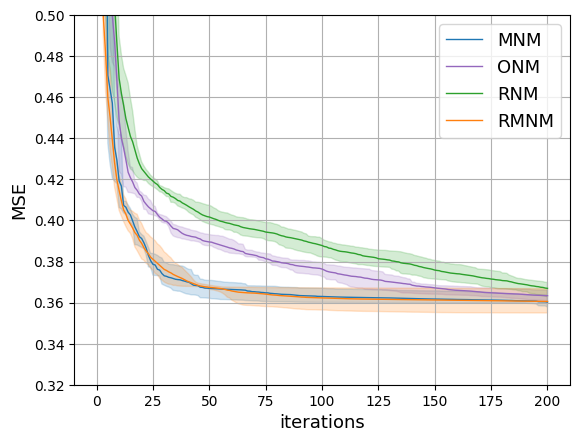

In [87]:
import os, sys

sys.path.append('../../')
from utils import plot_psd, nmse

%matplotlib inline
import matplotlib

import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 1
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['mnm_lev_marq', 'newton_lev_marq', 'cubic_newton', 'cubic_newton_simple']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}_real_init_{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

colors = ['#1f77b4', '#9467bd', '#2ca02c', '#ff7f0e']
alpha=0.2

# ax.plot(lc_min[0, :], color=colors[0], linestyle='dashed', label='newt_min', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[0], linestyle='solid', label='newt_aver', linewidth=1)
# ax.plot(lc_max[0, :], color=colors[0], linestyle='dashed', label='newt_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[0], alpha=alpha)

# ax.plot(lc_min[1, :], color=colors[1], linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[1], linestyle='solid', label='cubic_aver', linewidth=1)
# ax.plot(lc_max[1, :], color=colors[1], linestyle='dashed', label='cubic_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[1], alpha=alpha)

# ax.plot(lc_min[2, :], color=colors[2], linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[2, :], color=colors[2], linestyle='solid', label='cubic_aver', linewidth=1)
# ax.plot(lc_max[2, :], color=colors[2], linestyle='dashed', label='cubic_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[2, :])), lc_min[2, :], lc_max[2, :], color=colors[2], alpha=alpha)

# ax.plot(lc_min[3, :], color=colors[3], linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[3, :], color=colors[3], linestyle='solid', label='cubic_aver', linewidth=1)
# ax.plot(lc_max[3, :], color=colors[3], linestyle='dashed', label='cubic_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[3, :])), lc_min[3, :], lc_max[3, :], color=colors[3], alpha=alpha)

plt.xlabel('iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
ax.legend(
# handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
#                     plt.gca().get_lines()[3], plt.gca().get_lines()[4],
#           plt.gca().get_lines()[6], plt.gca().get_lines()[7], 
# plt.gca().get_lines()[9], plt.gca().get_lines()[10]],
    handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[2], plt.gca().get_lines()[3]],
          labels=['MNM',
                            'ONM',
                            'RNM',
                            'RMNM'], fontsize=13)
                    # labels=['MNM, min-max range', 'MNM, mean',
                    #         'ONM, min-max range', 'OMN, mean',
                    #         'RNM, min-max range', 'RNM, mean',
                    #         'RMNM, min-max range', 'RMNM, mean'], fontsize=10)

plt.ylim(0.32, 0.5)
plt.grid()

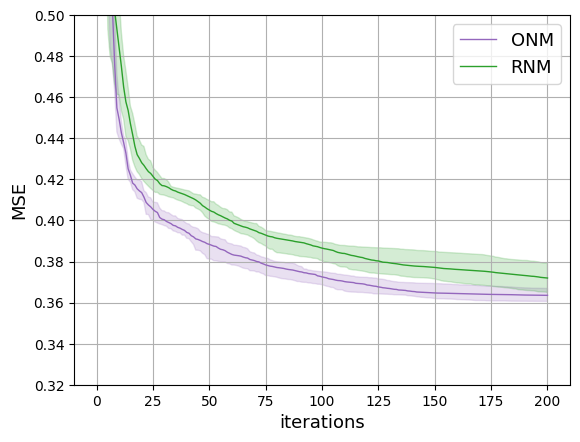

In [88]:
# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 1
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['newton_lev_marq', 'cubic_newton']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"real_hidden=10_std=0.1_{method}__{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

colors = ['#1f77b4', '#9467bd', '#2ca02c', '#ff7f0e']
alpha=0.2

# ax.plot(lc_min[0, :], color=colors[0], linestyle='dashed', label='newt_min', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[1], linestyle='solid', label='newt_aver', linewidth=1)
# ax.plot(lc_max[0, :], color=colors[0], linestyle='dashed', label='newt_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[1], alpha=alpha)

# ax.plot(lc_min[1, :], color=colors[1], linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[2], linestyle='solid', label='cubic_aver', linewidth=1)
# ax.plot(lc_max[1, :], color=colors[1], linestyle='dashed', label='cubic_max', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[2], alpha=alpha)


plt.xlabel('iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
ax.legend(
# handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
#                     plt.gca().get_lines()[3], plt.gca().get_lines()[4],
#           plt.gca().get_lines()[6], plt.gca().get_lines()[7], 
# plt.gca().get_lines()[9], plt.gca().get_lines()[10]],
    handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1]],
          labels=['ONM',
                    'RNM'], fontsize=13)
                    # labels=['MNM, min-max range', 'MNM, mean',
                    #         'ONM, min-max range', 'OMN, mean',
                    #         'RNM, min-max range', 'RNM, mean',
                    #         'RMNM, min-max range', 'RMNM, mean'], fontsize=10)

plt.ylim(0.32, 0.5)

plt.grid()

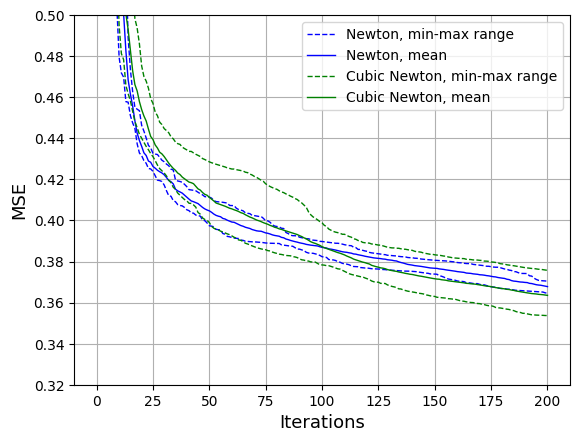

In [71]:
import os, sys

sys.path.append('../../')
from utils import plot_psd, nmse

%matplotlib inline
import matplotlib

import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 1
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['newton_lev_marq', 'cubic_newton']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}_imaginary_init_{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

ax.plot(lc_min[0, :], color='blue', linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[0, :], color='blue', linestyle='solid', label='cubic_aver', linewidth=1)
ax.plot(lc_max[0, :], color='blue', linestyle='dashed', label='cubic_max', linewidth=1)

ax.plot(lc_min[1, :], color='green', linestyle='dashed', label='cubic_min', linewidth=1)
ax.plot(lc_aver[1, :], color='green', linestyle='solid', label='cubic_aver', linewidth=1)
ax.plot(lc_max[1, :], color='green', linestyle='dashed', label='cubic_max', linewidth=1)

plt.xlabel('Iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
ax.legend(handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[3], plt.gca().get_lines()[4]],
                    labels=['Newton, min-max range', 'Newton, mean',
                            'Cubic Newton, min-max range', 'Cubic Newton, mean'], fontsize=10)

plt.ylim(0.32, 0.5)

plt.grid()